# Linear Regression

In [37]:
import os
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

import statsmodels.formula.api as smf

In [38]:
obs = pd.read_csv(
    '/Users/kellyanne/Desktop/meds2027/eds220/eds220-2026-sections/data/55_Hare_Data_2012.txt')
obs.head()

,date,time,grid,trap,l_ear,r_ear,sex,age,weight,hindft,notes,b_key,session_id,study
0,11/26/1998,NaN,bonrip,1A,414D096A08,NaN,NaN,NaN,1370.0,160.0,NaN,917.0,51,Population
1,11/26/1998,NaN,bonrip,2C,414D320671,NaN,M,NaN,1430.0,NaN,NaN,936.0,51,Population
2,11/26/1998,NaN,bonrip,2D,414D103E3A,NaN,M,NaN,1430.0,NaN,NaN,921.0,51,Population
3,11/26/1998,NaN,bonrip,2E,414D262D43,NaN,NaN,NaN,1490.0,135.0,NaN,931.0,51,Population
4,11/26/1998,NaN,bonrip,3B,414D2B4B58,NaN,NaN,NaN,1710.0,150.0,NaN,933.0,51,Population


In [39]:
obs['date'] = pd.to_datetime(obs['date'])
print(obs['date'].dtype)

datetime64[ns]


## 

In [40]:
obs['age'].value_counts(dropna = False)

age
NaN          2111
A             564
J             267
a             183
j             128
1/2/2013       21
1/4/2013       21
3/4/2013       18
1              12
U              11
?              10
a 3/4 yr.       4
2 yrs.          3
u               3
A 3/4           2
1.5             2
3.5 yrs.        2
2.25 yrs        2
1 yr.           2
1 yr            2
a 1 yr.         2
A 1.5           1
2.5 yrs         1
3 yrs.          1
a 2 yrs.        1
J 3/4           1
2 yrs           1
A 1/2           1
a 1 yr          1
1.25            1
3.25 yrs.       1
Name: count, dtype: int64

When you make a decision, document it !
We will keep all hares with j as juvenile, and all hares with a as an adult.

In [41]:
# Update the age values to juvenile and adult for the observations wehre 'a' and 'j' are included
obs.loc[obs['age'].str.contains('j', case = False, na = False), 'age'] = 'juvenile'
obs.loc[obs['age'].str.contains('a', case = False, na = False), 'age'] = 'adult'

# Filter for confirmed observations of juvenile and adult hares
obs_juv_adult = obs[obs['age'].isin(['juvenile', 'adult'])].copy()
print('Number of juvenile and adult hare observations (captures):', len(obs_juv_adult)) 

Number of juvenile and adult hare observations (captures): 1155


In [42]:
# Extract year in which each observation happened
obs_juv_adult['year'] = obs_juv_adult['date'].dt.year

In [43]:
# Count observations per year and age, then move age values into columns
obs_per_year = obs_juv_adult.groupby(['year', 'age']).size().unstack() # splits index into its own column
obs_per_year

age,adult,juvenile
year,,
1999,150.0,126.0
2000,159.0,67.0
2001,72.0,22.0
2002,3.0,NaN
2003,1.0,18.0
2004,NaN,8.0
2005,95.0,48.0
2006,101.0,15.0
2007,13.0,5.0


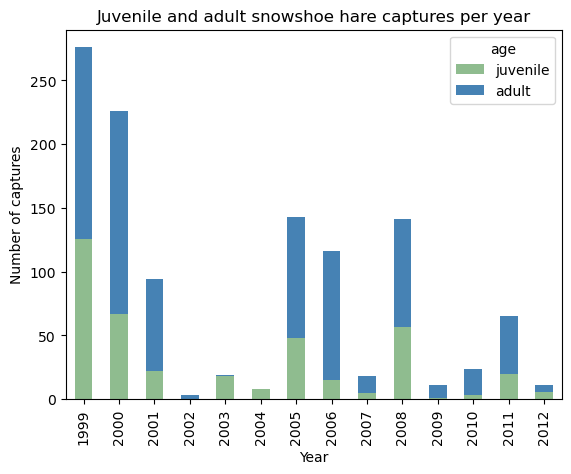

In [44]:
obs_per_year[['juvenile', 'adult']].plot(kind='bar',                  # Columns in stacking order
                                         stacked=True,                # Stack the bars
                                         color=['#8FBC8F', '#4682B4'],
                                         title='Juvenile and adult snowshoe hare captures per year',
                                         xlabel='Year',
                                         ylabel='Number of captures');

## Check in
Consider the following questions:

In what ways could the data collection methods affect the results we see here?
Is there additional metadata you would need to better understand the data?

# Ploting with `matplotlib`
## `matplotlib`'s `fig` and `axis`

Matplotlib graphs the data in a **figure** which can have one or more **axes**. The axes is only the area specified by the x-axis and y-axis and what is plotted in it, while the figure can include multiple axes in it.

![alt text](https://meds-eds-220.github.io/MEDS-eds-220-course/book/images/lesson-10/matplotlib_figure_axes_axis.png)

To create a new blank figure:

1. Initialize a new figure and axes by calling pyplot’s subplots() function
2. Display the figure using plt.show():

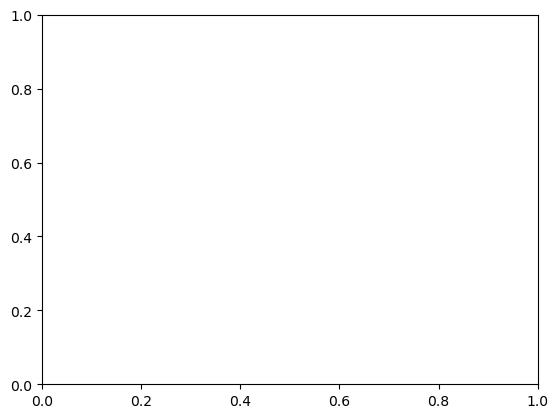

In [45]:
# Initialize empty figure (fig) and axes (ax)
fig, ax = plt.subplots()

# Display figure
plt.show()

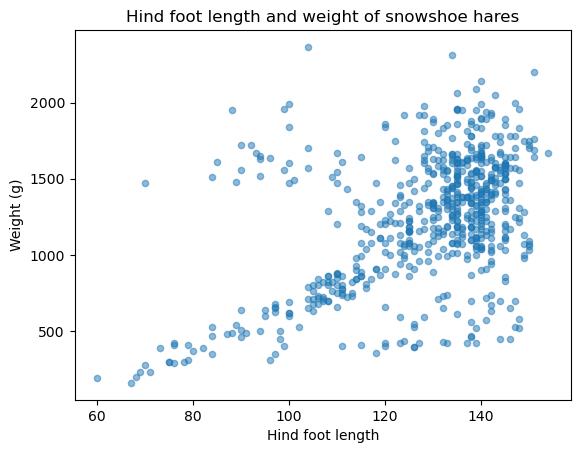

In [47]:
# Initialize empty figure and axes
fig, ax = plt.subplots()

# Add scatter plot of hares' data to our figure's axes
obs_juv_adult.plot(kind='scatter', x='hindft', y='weight', ax=ax, alpha = 0.5)

# Update axis
ax.set_title("Hind foot length and weight of snowshoe hares")
ax.set_xlabel("Hind foot length")
ax.set_ylabel("Weight (g)")

# Display figure
plt.show()

## Customization
Matplotlib allows for a lot of customization. Some of it can be done directly in the plot() method for the data frame (like we’ve done when plotting data using pandas), while other is done by updating attributes of the ax axes. The following diagram shows some examples of elements in the axes that can be updated.

![Image source: Matplotlib documentation.
](https://meds-eds-220.github.io/MEDS-eds-220-course/book/images/lesson-10/anatomy.png)


# Linear Regression
For our analysis we want to investigate possible relations between hind foot length and weight for juvenile hares. Let’s take a look at our target data:

Number of juvenile hare captures: 265


<Axes: xlabel='hindft', ylabel='weight'>

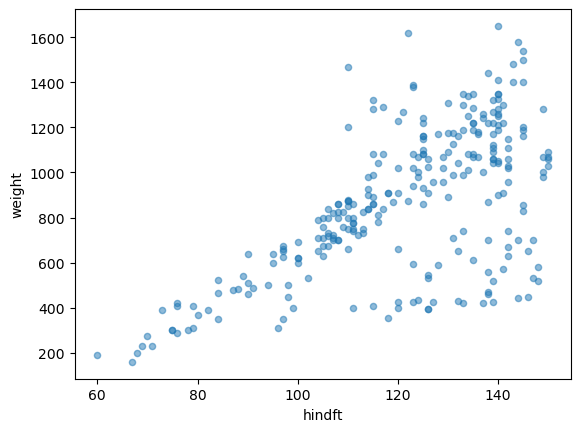

In [50]:
# Subset juvenile hares and drop rows missing hind foot or weight measurements
juv_w_hft = obs_juv_adult[obs_juv_adult['age'] == 'juvenile'].dropna(subset=['hindft', 'weight'])

print("Number of juvenile hare captures:", len(juv_w_hft))
juv_w_hft.plot.scatter(x='hindft', y='weight', alpha=0.5)

Remember from our bar plot that the number of captures changed a lot from year to year: our regression combines juveniles from all years, and almost a third of them (79 of 265) were captured in 1999.

We can see there seems to be a linear trend between the weight and hind foot length variables, though as the hind foot length increases the variability does too.

Let’s investigate whether a linear model is an adequate way to describe this data. To do this we will use the statsmodels library, which has tools for fitting statistical models. At the top of the notebook we imported it as `smf`.

To fit the model we use the `ols()` function, short for ordinary least squares, the method that finds the line that minimizes the sum of the squared vertical distances between the data points and the line. It takes two arguments:

a formula of the form 'response ~ predictor', a string that we can read as “response explained by predictor”. The names in the formula are the names of the columns in our data frame.
data: the data frame with those columns.

`ols()` sets up the model, and calling `fit()` on it estimates the coefficients:

In [51]:
# Fit model: weight explained by hind foot length
model = smf.ols('weight ~ hindft', data=juv_w_hft).fit()

In [52]:
model.params

Intercept   -352.771986
hindft        10.092240
dtype: float64

The Intercept value is Beta 0, and the hindft value is Beta 1, the slope for the hind foot length. Let’s save them in variables to use them later:

In [53]:
# Retrieve intercept and slope
intercept = model.params['Intercept']
print("y-intercept:", intercept)

slope = model.params['hindft']
print("Slope:", slope)

y-intercept: -352.77198564640645
Slope: 10.092239638623006


We can also look at the **coefficient of determination**, R^2. This is between 0 and 1, with R^2 = 1 describing a perfect fit of the model to the data. 

The R^2 value is interpreted as the proportion of variance in the response "y" that is explained by the least squares line with the predictor "x".

This value is stored in the model’s `rsquared` attribute:

In [54]:
print("R^2:", model.rsquared)

R^2: 0.3871164783665738


In [58]:
# Smallest and largest hind foot lengths
x_start = juv_w_hft['hindft'].min()
x_end = juv_w_hft['hindft'].max()
print(x_start, x_end)

60.0 150.0


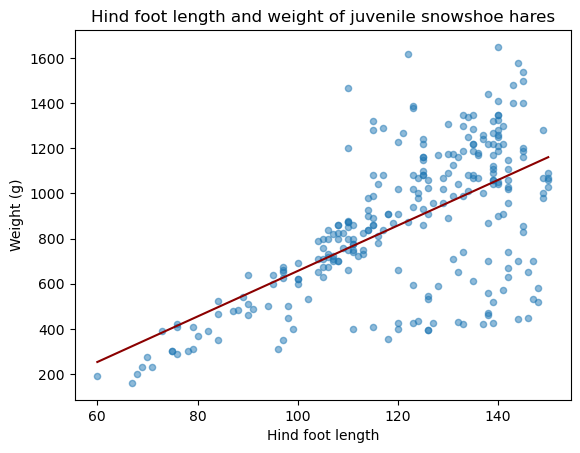

In [60]:
# Initialize empty figure and axes
fig, ax = plt.subplots()

# Add scatter plot of hares' data to our figure's axes
juv_w_hft.plot(kind='scatter', x='hindft', y='weight', ax=ax, alpha = 0.5)

# Add regression line to axis
ax.plot([x_start, x_end],
        [intercept + slope*x_start, intercept + slope*x_end],
        color = 'darkred')

# Update axis
ax.set_title("Hind foot length and weight of juvenile snowshoe hares")
ax.set_xlabel("Hind foot length")
ax.set_ylabel("Weight (g)")

# Display figure
plt.show()

## Checking the residuals
R^2 tells us how much of the variation the model explains, but not whether a straight line is the right shape for the data. One check for this is looking at the residuals. A residual is the difference between an observed value and the value predicted by the model.

The residuals are the "E" in our model equation, so the model assumes they are normally distributed around 0, and that they spread out about the same amount for short and long hind feet. statsmodels calculates the residuals for us and stores them in the model’s resid attribute.

In [64]:
model.resid

108    -523.850209
109    -609.864845
110    -655.510522
111    -397.835573
112    -549.403647
           ...    
3355    -46.820937
3359    117.625625
3360    117.625625
3367   -276.175259
3369    -37.189895
Length: 265, dtype: float64

<Axes: title={'center': 'Distribution of residuals'}, xlabel='Residual (g)', ylabel='Frequency'>

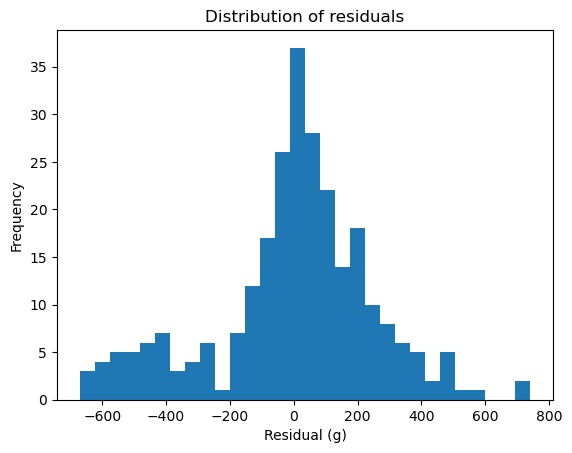

In [65]:
model.resid.plot(kind='hist', 
                 bins=30, 
                 title='Distribution of residuals', 
                 xlabel='Residual (g)')

The residuals are centered near 0 and roughly bell-shaped, but with a long tail of negative residuals: some hares weigh much less than the line predicts. Let’s see where these residuals come from.

If a linear model describes the data well, the residuals should be scattered randomly around 0, with about the same spread for every value of 
. Let’s plot them against the hind foot length. Since the residuals are not a column of our data frame, we plot them with the axes’ scatter() method, ax.scatter(x_values, y_values). We also add a horizontal reference line at 0 with ax.axhline():

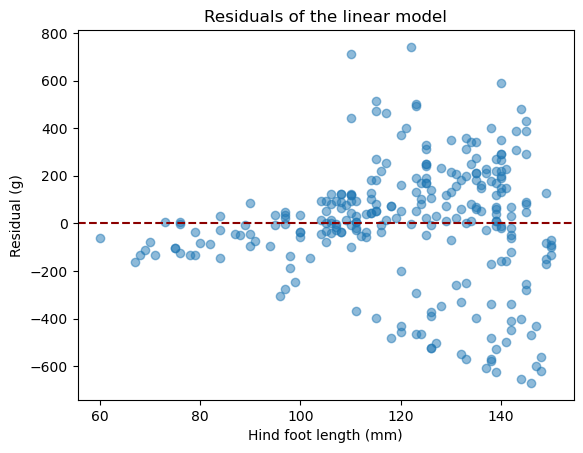

In [66]:
# Initialize empty figure and axes
fig, ax = plt.subplots()

# Add residuals to axes
ax.scatter(juveniles_weight_hindft['hindft'], model.resid, alpha=0.5)

# Add reference line at 0
ax.axhline(0, color='darkred', linestyle='--')

# Update axes
ax.set_title('Residuals of the linear model')
ax.set_xlabel('Hind foot length (mm)')
ax.set_ylabel('Residual (g)')

# Display figure
plt.show()

The residuals show three patterns:

- The spread grows with hind foot length. For short hind feet most residuals are within about 100 g of 0, while for the longest hind feet many are more than 300 g away. This is the increasing variability we noticed in the first scatter plot. It means the model’s predictions are less precise for larger juveniles.
- The residuals are not centered on 0 everywhere. For hind feet shorter than about 100 mm most residuals are negative (the line overestimates weight), while for medium hind feet they are mostly positive (the line underestimates weight). This suggests that the relationship between hind foot length and weight is not exactly linear.
- For longer hind feet the residuals split into two groups, one above and one below the line. This could mean that another variable also affects weight.
None of these patterns means the model is useless: the line still captures the overall trend. But they are a reminder that a single R^2 value doesn’t tell the whole story, and that we should be careful when using the model to make predictions, especially for larger juveniles.